# Día 1 · t-SNE: vecinos antes que islas
**14 de octubre de 2026 · 120 minutos · Atlas del movimiento humano**

Al terminar podrá explicar las afinidades de t-SNE, implementar su núcleo exacto
en una clase y auditar una visualización sin confundir separación gráfica con
distancia real. El notebook orquesta; la lógica vive en `manifold_lab`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'datasets/semana-09').is_dir())
PROJECT = ROOT / 'notebooks/semana-09/proyecto_reduccion'
sys.path.insert(0, str(PROJECT / 'src'))
DATA = ROOT / 'datasets/semana-09'
RESULTS = ROOT / 'notebooks/semana-09/resultados'

from manifold_lab import (HARDatasetLoader, TSNEConfig, UMAPConfig,
                          TSNEFromScratch, UMAPFromScratch,
                          EmbeddingEvaluator, EmbeddingResult)

dataset = HARDatasetLoader(DATA).load()
cache = np.load(RESULTS / 'embeddings_har.npz')
selected = cache['selected']
metadata = dataset.metadata.iloc[selected].reset_index(drop=True)
X50 = cache['pca50'].astype(float)
print(f'Muestra: {len(dataset.metadata):,} filas x {dataset.features.shape[1]} variables')
print(f'Atlas comparativo: {len(selected):,} filas; etiquetas ocultas durante el ajuste.')

D:\Documentos\Universidad Externado\Pregrado en Ciencia de Datos\Machine Learning 2\.venv-week9\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Muestra: 3,600 filas x 561 variables
Atlas comparativo: 1,800 filas; etiquetas ocultas durante el ajuste.


## 1. El contrato antes del algoritmo

Abra `base.py`, `config.py` y `results.py`. Identifique qué responsabilidades
quedan fuera de `TSNEFromScratch`. ¿Qué código espagueti evita esa separación?

**Respuesta:** _describa una responsabilidad y una dependencia_.

In [2]:
from manifold_lab.base import BaseEmbeddingReducer
print(TSNEFromScratch.__mro__)
model = TSNEFromScratch(TSNEConfig(perplexity=8, n_iter=80))
print(model.name, model.get_params())

(<class 'manifold_lab.tsne.TSNEFromScratch'>, <class 'manifold_lab.base.BaseEmbeddingReducer'>, <class 'abc.ABC'>, <class 'object'>)
t-SNE desde cero {'perplexity': 8, 'learning_rate': 100.0, 'n_iter': 80, 'early_exaggeration': 4.0, 'exaggeration_iter': 100, 'random_state': 42}


## 2. De distancias a probabilidades locales

Para cada punto (i):

$$p_{j|i}=\frac{\exp(-\beta_i\lVert x_i-x_j\rVert^2)}
{\sum_{k\ne i}\exp(-\beta_i\lVert x_i-x_k\rVert^2)}.$$

La búsqueda binaria de β ajusta la entropía hasta que
(\exp(H(P_i))\) coincide con la perplejidad. No es un número rígido de vecinos.

In [3]:
from sklearn.datasets import make_s_curve
from manifold_lab.tsne import joint_probabilities

toy, color = make_s_curve(100, noise=.03, random_state=42)
P = joint_probabilities(toy, perplexity=12)
assert np.allclose(P, P.T) and np.isclose(P.sum(), 1)
print('P simétrica:', np.allclose(P, P.T), '| suma:', P.sum())

P simétrica: True | suma: 1.0


## 3. El mapa paga por vecinos inventados

En dos dimensiones se usa una Student-t:

$$q_{ij}=\frac{(1+\lVert y_i-y_j\rVert^2)^{-1}}
{\sum_{k\ne l}(1+\lVert y_k-y_l\rVert^2)^{-1}},\qquad
C=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.$$

KL es asimétrica: colocar juntos puntos que no eran vecinos recibe una sanción
especialmente fuerte. Las distancias entre islas no quedan calibradas.

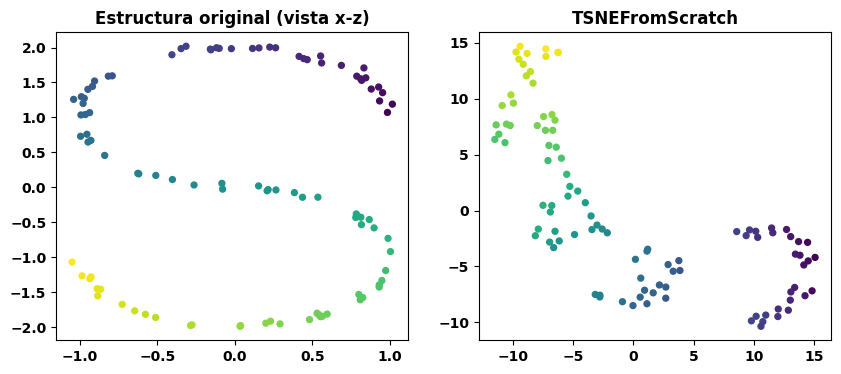

KL registrada: [0.2174 0.2166 0.2159 0.2152 0.2147]


In [4]:
small = TSNEFromScratch(TSNEConfig(perplexity=12, n_iter=300,
                                   learning_rate=40, random_state=42))
Y = small.fit_transform(toy)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(toy[:, 0], toy[:, 2], c=color, cmap='viridis', s=18)
axes[0].set_title('Estructura original (vista x-z)')
axes[1].scatter(*Y.T, c=color, cmap='viridis', s=18)
axes[1].set_title('TSNEFromScratch')
plt.show()
print('KL registrada:', np.round(small.history_[-5:], 4))

### Para resolver

Cambie la semilla y la perplejidad. Registre qué vecindarios sobreviven y qué
propiedades visuales cambian sin evidencia suficiente.

**Mi evidencia:** _incluya una comparación y una limitación_.

## 4. Un atlas admite más de una historia

Las etiquetas no se usaron para ajustar. Colorear después por actividad ayuda a
interpretar; colorear por participante sirve para detectar una explicación rival.

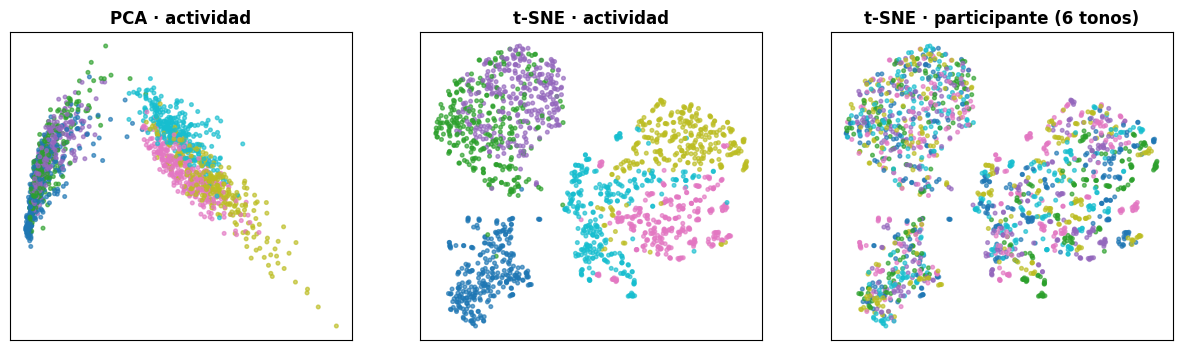

In [5]:
activity = pd.Categorical(metadata.activity).codes
subjects = (metadata.subject.to_numpy() - 1) % 6
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, title, labels in [
    (axes[0], 'pca', 'PCA · actividad', activity),
    (axes[1], 'tsne_30', 't-SNE · actividad', activity),
    (axes[2], 'tsne_30', 't-SNE · participante (6 tonos)', subjects),
]:
    ax.scatter(*cache[key].T, c=labels, cmap='tab10', s=7, alpha=.65)
    ax.set(title=title, xticks=[], yticks=[])
plt.show()

In [6]:
evaluator = EmbeddingEvaluator(n_neighbors=15)
rows = []
for key in ['pca', 'tsne_5', 'tsne_30', 'tsne_80']:
    result = EmbeddingResult(key, cache[key].astype(float), {}, 0.0)
    rows.append({'método': key, **evaluator.evaluate(X50, result).as_dict()})
pd.DataFrame(rows).round(3)

,método,trustworthiness,neighbor_overlap,distance_correlation,duration_seconds
0,pca,0.898,0.122,0.961,0.0
1,tsne_5,0.971,0.375,0.658,0.0
2,tsne_30,0.978,0.411,0.776,0.0
3,tsne_80,0.978,0.399,0.877,0.0


## Ticket individual

1. ¿Qué controla realmente la perplejidad?
2. ¿Por qué no puede comparar literalmente la distancia entre dos islas?
3. ¿Qué evidencia pediría antes de llamar “actividad” a un grupo?